In [1]:
import re
import html
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

for pkg in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg, quiet=True)

os.makedirs("reports/figures", exist_ok=True)

stemmer = PorterStemmer()
stop_words = set(stopwords.words("english"))


[nltk_data] Error loading punkt: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading punkt_tab: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading stopwords: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


In [2]:
# text cleaning function
def clean_text(text: str) -> str:
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"(http\S+|www\.\S+)", " urltoken ", text)
    text = re.sub(r"\b\d{9,}\b", " phonetoken ", text)
    text = re.sub(r"[£$€]\s?\d[\d,\.]*", " currencytoken ", text)
    text = re.sub(r"\d+", " numtoken ", text)
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

In [3]:
# load the final model
model = joblib.load("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/spam_pipeline.pkl")
print("Loaded:", model.named_steps["clf"])

Loaded: LogisticRegression(C=50, class_weight='balanced', max_iter=2000,
                   random_state=42)


In [4]:
# build  a custom test set
custom = [
    # (category, expected, message)
    ("NG scam / spam", "spam", "Congratulations! You have won N5,000,000 in the MTN promo. Send your account details to claim now"),
    ("NG scam / spam", "spam", "URGENT! Your MTN line will be blocked. Click http://bit.ly/mtn-verify to update your details"),
    ("NG scam / spam", "spam", "Dear customer, your BVN has been suspended. Visit www.gtb-update.com now to reactivate"),
    ("NG scam / spam", "spam", "FREE data! Dial *123*1# or text WIN to 3030 to get 10GB free. Offer ends tonight"),
    ("NG scam / spam", "spam", "Earn N50,000 daily from home! No experience needed. WhatsApp 08031234567 to join now"),
    ("NG scam / spam", "spam", "You have been selected for a CBN grant of N500,000. Reply with your full name and account number"),
    ("NG scam / spam", "spam", "Airtel: You have won a free iPhone 15. Call 08098765432 now to claim your prize"),

    ("NG bank / telecom (legit)", "ham", "Dear customer, your account has been credited with NGN 25,000. Bal: NGN 40,200"),
    ("NG bank / telecom (legit)", "ham", "Your OTP is 482913. It expires in 5 minutes. Do not share it with anyone."),
    ("NG bank / telecom (legit)", "ham", "Debit alert: NGN 3,500.00 spent at Shoprite Lekki. Available balance NGN 12,300.50"),
    ("NG bank / telecom (legit)", "ham", "Your data bundle of 5GB will expire on 30 Nov. Dial *312# to check your balance"),

    ("Pidgin / casual", "ham", "Abeg call me when you reach house, I dey wait"),
    ("Pidgin / casual", "ham", "How far? You dey come church tomorrow?"),
    ("Pidgin / casual", "ham", "Wetin dey happen? I don try call you since morning"),
    ("Pidgin / casual", "ham", "I no go fit come today, traffic too much for Lekki. Make we talk tomorrow"),

    ("Standard English ham", "ham", "Meeting has been moved to 3pm tomorrow. Please confirm."),
    ("Standard English ham", "ham", "Please send the project report before 5pm today"),
    ("Standard English ham", "ham", "Happy birthday! Wishing you a wonderful year ahead"),

    ("UK-style spam (control)", "spam", "Free entry! Text WIN to 80086 to get a chance to win a free iPhone"),
    ("UK-style spam (control)", "spam", "WINNER!! You have been selected to receive a £900 prize. Call 09061701461 now"),
]

custom_df = pd.DataFrame(custom, columns=["category", "expected", "message"])
print(custom_df.shape)
custom_df["category"].value_counts()

(20, 3)


category
NG scam / spam               7
NG bank / telecom (legit)    4
Pidgin / casual              4
Standard English ham         3
UK-style spam (control)      2
Name: count, dtype: int64

In [5]:
# make prediction
custom_df["clean"] = custom_df["message"].apply(clean_text)
custom_df["pred_num"] = model.predict(custom_df["clean"])
custom_df["predicted"] = custom_df["pred_num"].map({0: "ham", 1: "spam"})

# spam score (probability if available, otherwise the SVM decision score)
clf = model.named_steps["clf"]
if hasattr(model, "predict_proba"):
    custom_df["spam_score"] = model.predict_proba(custom_df["clean"])[:, 1].round(3)
else:
    custom_df["spam_score"] = model.decision_function(custom_df["clean"]).round(3)

custom_df["correct"] = custom_df["expected"] == custom_df["predicted"]
custom_df[["category", "message", "expected", "predicted", "spam_score", "correct"]]


,category,message,expected,predicted,spam_score,correct
0,NG scam / spam,"Congratulations! You have won N5,000,000 in the MTN promo. Send your account details to claim now",spam,spam,0.603,True
1,NG scam / spam,URGENT! Your MTN line will be blocked. Click http://bit.ly/mtn-verify to update your details,spam,spam,0.811,True
2,NG scam / spam,"Dear customer, your BVN has been suspended. Visit www.gtb-update.com now to reactivate",spam,spam,0.885,True
3,NG scam / spam,FREE data! Dial *123*1# or text WIN to 3030 to get 10GB free. Offer ends tonight,spam,spam,0.987,True
4,NG scam / spam,"Earn N50,000 daily from home! No experience needed. WhatsApp 08031234567 to join now",spam,spam,0.896,True
5,NG scam / spam,"You have been selected for a CBN grant of N500,000. Reply with your full name and account number",spam,spam,0.779,True
6,NG scam / spam,Airtel: You have won a free iPhone 15. Call 08098765432 now to claim your prize,spam,spam,1.000,True
7,NG bank / telecom (legit),"Dear customer, your account has been credited with NGN 25,000. Bal: NGN 40,200",ham,spam,0.860,False
8,NG bank / telecom (legit),Your OTP is 482913. It expires in 5 minutes. Do not share it with anyone.,ham,ham,0.066,True
9,NG bank / telecom (legit),"Debit alert: NGN 3,500.00 spent at Shoprite Lekki. Available balance NGN 12,300.50",ham,ham,0.376,True


In [6]:
# Overall and per-category results
print("Overall accuracy on custom messages:",
      round(custom_df["correct"].mean() * 100, 1), "%",
      f"({custom_df['correct'].sum()}/{len(custom_df)})")

summary = (custom_df.groupby("category")["correct"]
           .agg(correct="sum", total="count")
           .assign(accuracy=lambda d: (d["correct"] / d["total"]).round(2)))
summary

Overall accuracy on custom messages: 95.0 % (19/20)


,correct,total,accuracy
category,,,
NG bank / telecom (legit),3,4,0.75
NG scam / spam,7,7,1.00
Pidgin / casual,4,4,1.00
Standard English ham,3,3,1.00
UK-style spam (control),2,2,1.00


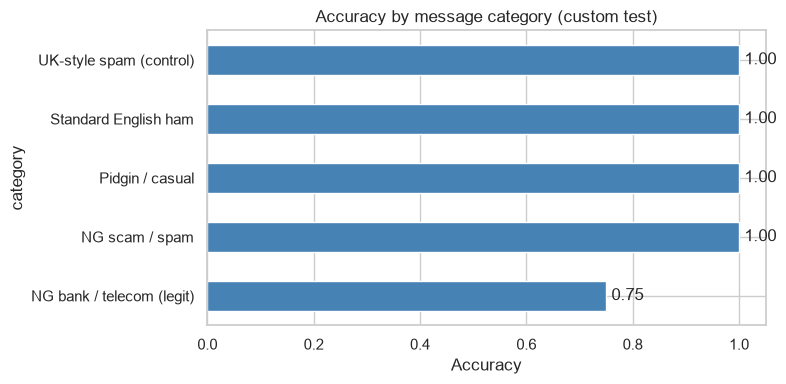

In [7]:
ax = summary["accuracy"].sort_values().plot(kind="barh", figsize=(8, 4), color="steelblue")
ax.set_xlim(0, 1.05)
ax.set_title("Accuracy by message category (custom test)")
ax.set_xlabel("Accuracy")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.2f}", (p.get_width() + 0.01, p.get_y() + p.get_height() / 2),
                va="center")
plt.tight_layout()
plt.savefig("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/figures/custom_test_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# misclassified messages
wrong = custom_df[~custom_df["correct"]]
print(f"Misclassified: {len(wrong)}\n")
wrong[["category", "message", "expected", "predicted", "spam_score", "clean"]]


Misclassified: 1



,category,message,expected,predicted,spam_score,clean
7,NG bank / telecom (legit),"Dear customer, your account has been credited with NGN 25,000. Bal: NGN 40,200",ham,spam,0.86,dear custom account credit ngn numtoken numtoken bal ngn numtoken numtoken


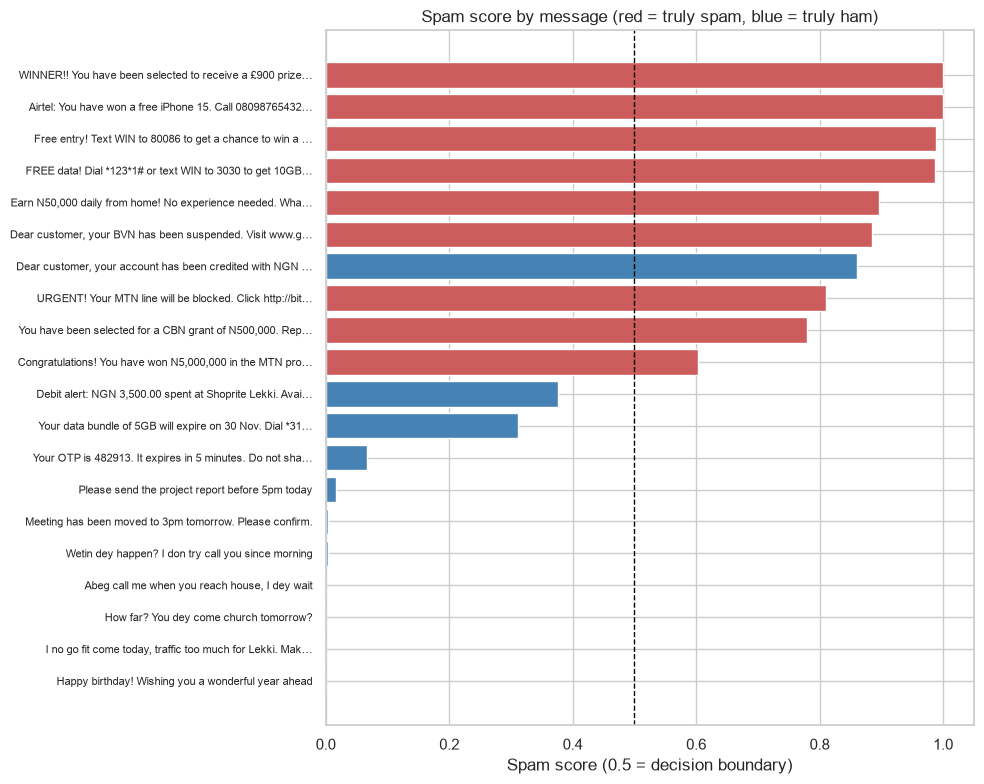

In [10]:
# spam score per message
plot_df = custom_df.sort_values("spam_score")
colors = plot_df["expected"].map({"spam": "indianred", "ham": "steelblue"})

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(plot_df)), plot_df["spam_score"], color=colors)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels([m[:55] + "…" if len(m) > 55 else m for m in plot_df["message"]], fontsize=8)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_title("Spam score by message (red = truly spam, blue = truly ham)")
ax.set_xlabel("Spam score (0.5 = decision boundary)")
plt.tight_layout()
plt.savefig("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/figures/custom_test_scores.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# save result
custom_df.drop(columns=["pred_num"]).to_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/custom_test_results.csv", index=False)
print("Saved reports/custom_test_results.csv")

Saved reports/custom_test_results.csv
